# Prueba NISAR con tu propio token Earthdata

Este notebook busca observaciones reales de NISAR, lee únicamente recortes
científicos mediante HTTPS, aplica un modelo congelado y muestra **agua azul y
borde cian**, incertidumbre y evolución temporal. Cada persona utiliza su propio
token **Bearer** de [NASA Earthdata Login](https://urs.earthdata.nasa.gov/).

**Modelo experimental:** ninguno de los candidatos está aprobado para uso
general. Este ejemplo ejecuta inferencia, no mide precisión ni demuestra una
causa humana del cambio. No requiere una imagen óptica despejada.

En Jupyter local: clona el repositorio, entra en `nisar-water`, ejecuta
`uv sync --frozen --extra notebook` y `uv run --no-sync jupyter lab`.
En Colab: ejecuta las celdas en orden. La primera prepara un entorno de trabajo
aislado si hace falta; puede tardar unos minutos. Usa Python 3.12 o 3.13.

El token se introduce en un campo oculto, nunca se escribe en archivos, URLs,
catálogos ni salidas. No pegues el token en una celda de código.

## 1. Preparar el proyecto y el intérprete del modelo

In [11]:
from pathlib import Path
import importlib.util
import os
import subprocess
import sys
import urllib.request

if not (3, 12) <= sys.version_info[:2] < (3, 14):
    raise RuntimeError("Usa un kernel Python 3.12 o 3.13 para este ejemplo.")

REPOSITORY = "https://github.com/Ch0comilo/NISAR-Models.git"
candidates = [Path.cwd(), Path.cwd() / "nisar-water", Path.cwd().parent,
              Path("/content/NISAR-Models/nisar-water")]
PROJECT_ROOT = next((p.resolve() for p in candidates
                     if (p / "pyproject.toml").is_file()
                     and (p / "checkpoints/manifest.json").is_file()), None)
if PROJECT_ROOT is None:
    destination = Path.cwd() / "NISAR-Models"
    if not destination.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPOSITORY, str(destination)], check=True)
    PROJECT_ROOT = (destination / "nisar-water").resolve()
    if not (PROJECT_ROOT / "checkpoints/manifest.json").is_file():
        raise RuntimeError("No se encontró nisar-water/checkpoints en el repositorio clonado.")

python_name = "Scripts/python.exe" if os.name == "nt" else "bin/python"
WORKER_PYTHON = PROJECT_ROOT / ".venv" / python_name
if not WORKER_PYTHON.is_file():
    isolated = PROJECT_ROOT / ".venv-notebook"
    WORKER_PYTHON = isolated / python_name
    if not WORKER_PYTHON.is_file():
        print("Instalando python3-venv para soporte de entornos virtuales...")
        subprocess.run(["sudo", "apt-get", "update", "-y"], stdout=subprocess.DEVNULL)
        subprocess.run(["sudo", "apt-get", "install", "-y", "python3-venv"], stdout=subprocess.DEVNULL)
        subprocess.run([sys.executable, "-m", "venv", "--without-pip", str(isolated)], check=True)

    # Verificar si el venv tiene pip disponible, de lo contrario instalarlo usando get-pip.py
    has_pip = subprocess.run([str(WORKER_PYTHON), "-m", "pip", "--version"],
                             stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL).returncode == 0
    if not has_pip:
        print("Pip no detectado en el entorno virtual. Descargando e instalando get-pip.py...")
        get_pip_path = PROJECT_ROOT / "get-pip.py"
        urllib.request.urlretrieve("https://bootstrap.pypa.io/get-pip.py", str(get_pip_path))
        try:
            subprocess.run([str(WORKER_PYTHON), str(get_pip_path)], check=True)
        finally:
            if get_pip_path.exists():
                get_pip_path.unlink()

        print("Actualizando pip y setuptools en el entorno virtual...")
        subprocess.run([str(WORKER_PYTHON), "-m", "pip", "install", "--upgrade", "pip", "setuptools"], check=True)

    installed = subprocess.run([str(WORKER_PYTHON), "-c", "import nisar_water, h5py, sklearn"],
                               stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
    if installed.returncode:
        print("Instalando el entorno aislado de inferencia (capturando logs detallados)...")
        try:
            result = subprocess.run(
                [str(WORKER_PYTHON), "-m", "pip", "install", "-e", str(PROJECT_ROOT)],
                stdout=subprocess.PIPE,
                stderr=subprocess.PIPE,
                text=True,
                check=True
            )
        except subprocess.CalledProcessError as e:
            print("--- ERROR DURANTE LA INSTALACIÓN DE PIP ---")
            print("Salida estándar (STDOUT):")
            print(e.stdout)
            print("Salida de error (STDERR):")
            print(e.stderr)
            raise e

os.chdir(PROJECT_ROOT)
subprocess.run([str(WORKER_PYTHON), "-c", "from nisar_water.registry import load_model; load_model('checkpoints/round5/terrain_prior')"],
               cwd=PROJECT_ROOT, check=True)
print("Proyecto e intérprete listos; checkpoint conservador verificado.")

Pip no detectado en el entorno virtual. Descargando e instalando get-pip.py...
Actualizando pip y setuptools en el entorno virtual...
Instalando el entorno aislado de inferencia (capturando logs detallados)...
Proyecto e intérprete listos; checkpoint conservador verificado.


## 2. Elegir zona, fechas y modelo

El ejemplo usa Nam Theun 1, Laos, con dos observaciones compatibles de octubre
de 2026. Es una demostración conocida; sus resultados no constituyen una prueba
independiente. Sustituye `BBOX` y las fechas para probar tu zona.

Solo se admite **NISAR L-GCOV, frecuencia A, HH/HV, potencia gamma0 lineal**.
La ventana debe ser pequeña: como máximo 0,2° por lado con contexto y cuatro
millones de píxeles nativos. El modelo prepara una grilla de 20 m.

`MAX_OBSERVATIONS=2` limita deliberadamente el ejemplo. Usa **0** para procesar
todas las observaciones compatibles del intervalo dentro del presupuesto. Si
faltan datos, falla una lectura o se agota el presupuesto, se informa **partial**;
no se inventan resultados. Diferentes órbitas/geometrías forman series separadas.

In [12]:
import json
import uuid
from datetime import datetime, timezone

# Coordenadas WGS84: [oeste, sur, este, norte].
BBOX = [104.18, 18.34, 104.26, 18.42]
START_DATE = "2026-10-06"
END_DATE = "2026-10-27"
MODEL_PROFILE = "terrain_prior"  # radar | terrain | terrain_prior
MAX_OBSERVATIONS = 2            # 0 = todas las compatibles
TRANSFER_CAP_MIB = 256          # radar; hasta 128 MiB por adquisición

if MODEL_PROFILE not in {"radar", "terrain", "terrain_prior"}:
    raise ValueError("Selecciona un perfil incluido en el repositorio.")
west, south, east, north = BBOX
AOI = {"type": "Polygon", "coordinates": [[[west, south], [east, south],
        [east, north], [west, north], [west, south]]]}
run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid.uuid4().hex[:6]
OUTPUT = PROJECT_ROOT / "outputs" / ("earthdata-demo-" + run_id)
INPUT_CONFIG = PROJECT_ROOT / ".cache/notebook-inputs" / (run_id + ".geojson")
INPUT_CONFIG.parent.mkdir(parents=True, exist_ok=True)
INPUT_CONFIG.write_text(json.dumps(AOI, indent=2), encoding="utf-8")
MODEL = PROJECT_ROOT / "checkpoints/round5" / MODEL_PROFILE
CONTEXT_CACHE = PROJECT_ROOT / ".cache/terrain-context"
print("Zona:", BBOX, "| Fechas:", START_DATE, "a", END_DATE)
print("Perfil:", MODEL_PROFILE, "| Máximo:", MAX_OBSERVATIONS, "| Radar MiB:", TRANSFER_CAP_MIB)
print("La potencia científica se recorta; no se descargan gránulos completos.")

Zona: [104.18, 18.34, 104.26, 18.42] | Fechas: 2026-10-06 a 2026-10-27
Perfil: terrain_prior | Máximo: 2 | Radar MiB: 256
La potencia científica se recorta; no se descargan gránulos completos.


## 3. Introducir tu token Bearer

Obtén o genera tu token en tu propia cuenta de Earthdata Login y acepta los
acuerdos de acceso exigidos por NASA/ASF para el producto. Pega el token en el
campo oculto. Se acepta con o sin el prefijo `Bearer `.

Para un entorno automatizado también se acepta `EARTHDATA_TOKEN`; esta celda
lo retira del entorno del kernel al leerlo. Nunca añadas el valor al notebook,
al repositorio ni a los parámetros del comando.

In [13]:
from getpass import getpass

_bearer = os.environ.pop("EARTHDATA_TOKEN", None) or getpass("Token Bearer Earthdata (oculto): ")
_bearer = _bearer.strip()
if _bearer.lower().startswith("bearer "):
    _bearer = _bearer[7:].strip()
if not _bearer or any(c.isspace() for c in _bearer):
    _bearer = None
    raise ValueError("El token está vacío o contiene espacios. Ejecuta de nuevo esta celda.")
print("Credencial recibida en memoria. No se guardará ni se mostrará.")

Token Bearer Earthdata (oculto): ··········
Credencial recibida en memoria. No se guardará ni se mostrará.


## 4. Buscar, leer recortes y clasificar

La búsqueda usa metadatos públicos NASA CMR. Solo las lecturas científicas de
hosts NASA/ASF reciben el token. Cada rango debe ser confirmado por el servidor;
no existe una descarga completa como alternativa.

Los perfiles físicos pueden obtener DEM/HAND/JRC públicos en una caché local
(presupuesto adicional de hasta 128 MiB por región). El prior histórico es una
entrada aprendida, no una máscara obligatoria de agua. Contexto físico requerido
ausente produce **desconocido**, no terreno seco. El token se elimina de las
variables de este notebook al finalizar el comando, incluso si falla.

In [14]:
command = [str(WORKER_PYTHON), "-m", "nisar_water.cli", "aoi", str(INPUT_CONFIG),
           "--start", START_DATE, "--end", END_DATE, "--model", str(MODEL),
           "--output", str(OUTPUT), "--limit", str(MAX_OBSERVATIONS),
           "--transfer-cap-mib", str(TRANSFER_CAP_MIB)]
if MODEL_PROFILE != "radar":
    command += ["--context-cache", str(CONTEXT_CACHE)]

def run_authenticated(command, credential):
    child_environment = os.environ.copy()
    child_environment["EARTHDATA_TOKEN"] = credential
    try:
        result = subprocess.run(command, cwd=PROJECT_ROOT, env=child_environment,
                                stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                                text=True, timeout=1200)
    finally:
        child_environment.pop("EARTHDATA_TOKEN", None)
    # Extra protección si alguna dependencia incluye por accidente la credencial.
    safe_output = result.stdout.replace(credential, "[TOKEN OCULTO]")
    print(safe_output.replace(str(PROJECT_ROOT), "."))
    if result.returncode:
        raise RuntimeError("La ejecución no se completó. Revisa la categoría de error anterior.")

try:
    if not _bearer:
        raise ValueError("Ejecuta primero la celda del token.")
    run_authenticated(command, _bearer)
finally:
    _bearer = None

BATCH = json.loads((OUTPUT / "batch.json").read_text(encoding="utf-8"))
print("Estado:", BATCH["state"], "| Adquiridas:", BATCH["acquired_observations"],
      "| Candidatas compatibles:", BATCH["candidate_observations"])
print("Consulta completa:", BATCH["complete_for_compatible_query"],
      "| Radar transferido MiB:", round(BATCH["radar_body_bytes"] / 1024**2, 2))
if not BATCH["acquired_observations"]:
    print("No hay imágenes para mostrar. Cambia zona/fechas o revisa los recibos de adquisición.")

ACQUIRE 2026-10-10T22:29:54Z NISAR_L2_PR_GCOV_032_155_A_011_2005_DHDH_A_20261010T222954_20261010T223029_P05023_N_F_J_001
ACQUIRE 2026-10-22T22:29:55Z NISAR_L2_PR_GCOV_033_155_A_011_2005_DHDH_A_20261022T222955_20261022T223029_P05023_N_F_J_001
completed 2 observations ./outputs/earthdata-demo-20261030T000540Z-411971

Estado: completed | Adquiridas: 2 | Candidatas compatibles: 2
Consulta completa: True | Radar transferido MiB: 31.0


## 5. Ver agua y borde en cada observación

Azul = agua clasificada; cian = su borde; las zonas sin soporte no son agua ni
terreno seco. La primera imagen muestra el radar con la predicción y la segunda
la máscara de incertidumbre. Estos mapas son estimaciones experimentales.

Serie: 930129417ab445d9 | Track: 155 | Paso: A | Frame: 11
2026-10-10T22:29:54Z | Agua ha: 893.46 | Desconocido ha: 2.94 | No observado ha: 1.9


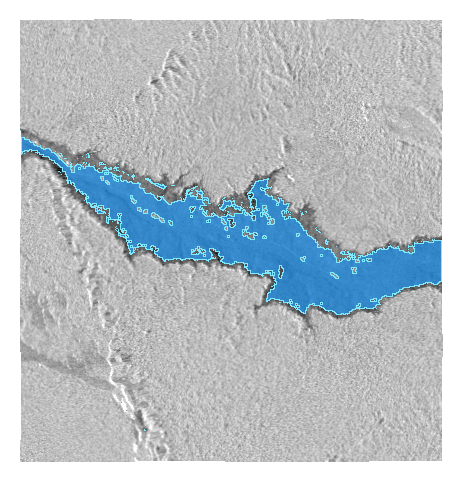

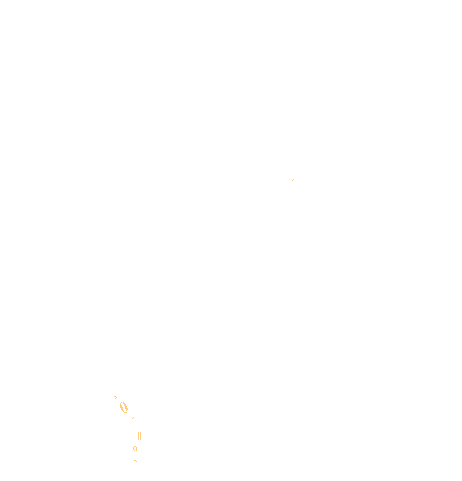

2026-10-22T22:29:55Z | Agua ha: 964.87 | Desconocido ha: 2.94 | No observado ha: 1.9


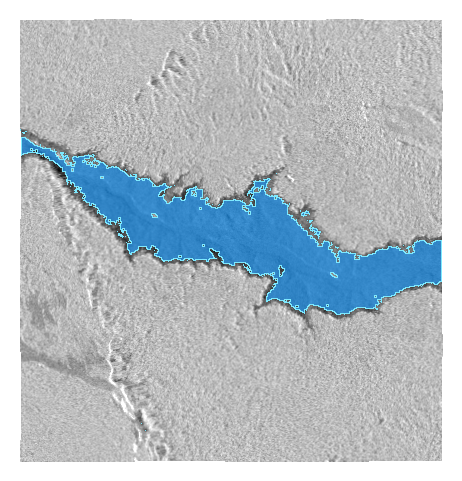

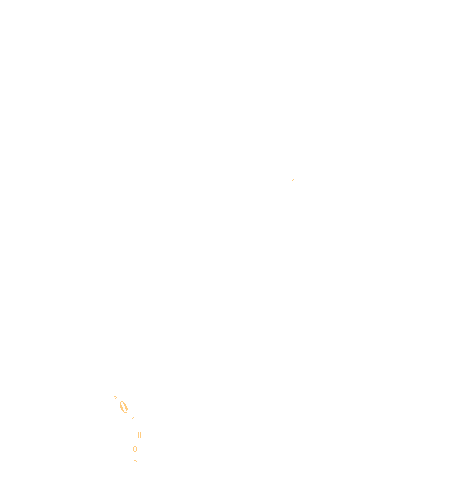

In [15]:
from IPython.display import display, Image, HTML
from html import escape

SERIES = []
for manifest_path in sorted(OUTPUT.rglob("series.json")):
    series = json.loads(manifest_path.read_text(encoding="utf-8"))
    SERIES.append((manifest_path, series))
    print("Serie:", series["id"], "| Track:", series["track"],
          "| Paso:", series["pass"], "| Frame:", series["frame"])
    for observation in series["observations"]:
        stats = observation["statistics"]
        print(observation["datetime"], "| Agua ha:", round(stats["waterHa"], 2),
              "| Desconocido ha:", round(stats["uncertainHa"], 2),
              "| No observado ha:", round(stats["unobservedHa"], 2))
        for asset_name in ("composite", "uncertain"):
            asset = observation["assets"].get(asset_name)
            if asset:
                path = manifest_path.parent / asset["url"].removeprefix("/assets/")
                display(Image(filename=str(path), width=700))

## 6. Evolución en soporte comparable

El área total puede cambiar porque cambia la cobertura. La tabla usa la
intersección clasificada compartida por **todas las fechas** de cada serie.
Las ganancias/pérdidas solo comparan píxeles clasificados en ambas fechas.
Una serie de una fecha no permite medir evolución. No mezcles órbitas distintas.
Agua variable no demuestra por sí sola una inundación ni actividad humana.

Serie: 930129417ab445d9


Fecha UTC,Agua comparable (ha),Soporte común (ha)
2026-10-10T22:29:54Z,893.46,7476.07
2026-10-22T22:29:55Z,964.87,7476.07


Cambio: comparable | Ganancia ha: 87.3720265483856 | Pérdida ha: 15.959999999999997 | Soporte ha: 7476.069861967715


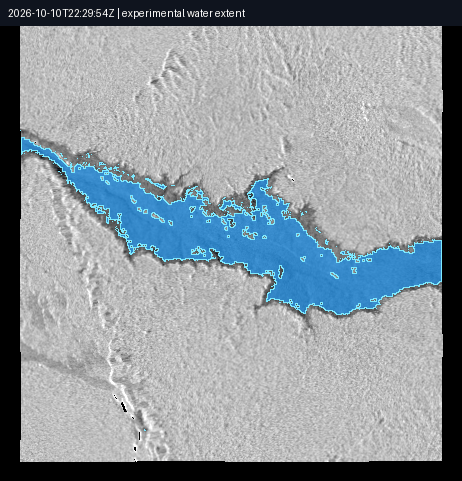

In [16]:
for manifest_path, series in SERIES:
    print("Serie:", series["id"])
    rows = []
    for row in series["timeline"]:
        water = row["waterOnCommonAllDatesHa"]
        rows.append("<tr><td>" + escape(row["datetime"]) + "</td><td>" +
                    ("Sin soporte" if water is None else f"{water:.2f}") + "</td><td>" +
                    f"{row['commonAllDatesHa']:.2f}" + "</td></tr>")
    display(HTML("<table><tr><th>Fecha UTC</th><th>Agua comparable (ha)</th>"
                 "<th>Soporte común (ha)</th></tr>" + "".join(rows) + "</table>"))
    for change in series["transitions"]:
        print("Cambio:", change["state"], "| Ganancia ha:", change["gainHa"],
              "| Pérdida ha:", change["lossHa"], "| Soporte ha:", change["commonClassifiedHa"])
    if series.get("animationUrl"):
        display(Image(filename=str(manifest_path.parent / series["animationUrl"].removeprefix("/assets/"))))

## 7. Probar el contrato API que consumirá la interfaz

Esta celda inicia temporalmente el servidor local, solicita `/health`,
`/water/assessment`, las series y una imagen de agua, verifica su SHA256 y lo
detiene al terminar. La salud del servidor **no** significa que el modelo esté
validado. El servicio actual publica resultados; no implementa envío HTTP de
trabajos de inferencia.

In [17]:
import hashlib
import socket
import time
from urllib.request import urlopen

with socket.socket() as available:
    available.bind(("127.0.0.1", 0))
    port = available.getsockname()[1]
api_command = [str(WORKER_PYTHON), "-m", "nisar_water.cli", "serve", "--root", str(OUTPUT),
               "--port", str(port), "--assessment", str(PROJECT_ROOT / "benchmarks/round5/assessment.json")]
server = subprocess.Popen(api_command, cwd=PROJECT_ROOT, stdout=subprocess.DEVNULL,
                          stderr=subprocess.DEVNULL,
                          creationflags=getattr(subprocess, "CREATE_NO_WINDOW", 0))
origin = f"http://127.0.0.1:{port}"
def api_json(path):
    with urlopen(origin + path, timeout=5) as response:
        return json.load(response)
try:
    for attempt in range(100):
        try:
            health = api_json("/health")
            break
        except OSError:
            if server.poll() is not None:
                raise RuntimeError("El servidor local no pudo iniciarse.")
            time.sleep(.2)
    else:
        raise TimeoutError("El servidor local no respondió a tiempo.")
    assessment = api_json("/water/assessment")
    entries = api_json("/water/series")
    print("Servicio:", health["state"], "| Modelo:", assessment["state"], "| Series:", len(entries))
    if entries:
        manifest = api_json(entries[0]["url"])
        asset = manifest["observations"][0]["assets"]["water"]
        with urlopen(origin + asset["url"], timeout=10) as response:
            png = response.read()
        assert hashlib.sha256(png).hexdigest() == asset["sha256"]
        print("PNG de agua servido por HTTP y SHA256 verificado.")
finally:
    server.terminate()
    try:
        server.wait(timeout=10)
    except subprocess.TimeoutExpired:
        server.kill()
        server.wait(timeout=5)

Servicio: ready | Modelo: not_ready_for_general_use | Series: 1
PNG de agua servido por HTTP y SHA256 verificado.


## 8. Exportar y repetir

Los resultados quedan en `outputs/earthdata-demo-...`: `series.json`,
`timeline.csv`, agua/borde PNG transparentes, COG con máscara/puntaje,
GeoJSON de agua y procedencia de contexto. Códigos: **0** no agua, **1** agua,
**254** observado pero desconocido/excluido, **255** no observado/fuera del AOI.
El puntaje es no calibrado; no lo muestres como una certeza verificada.

Para otra prueba: cambia zona/fechas/perfil, ejecuta desde la configuración e
introduce otra vez tu token. Cada ejecución crea un directorio nuevo. No
subas cachés, credenciales ni datos científicos al repositorio.

**Si falla:** `AUTHENTICATION_FAILED` pide revisar/renovar el token;
`AUTHORIZATION_OR_AGREEMENT_REQUIRED` pide revisar permisos/acuerdos Earthdata;
`TRANSFER_LIMIT` requiere reducir la prueba o aumentar su presupuesto explícito;
`no_compatible_data` indica ausencia del perfil soportado en la zona/fechas.
Un área desconocida grande requiere revisar soporte físico/geométrico.

Consulta `docs/notebook-earthdata.md`, `docs/api-integration.md` y la tarjeta del
modelo. La integración futura por API puede reutilizar el mismo worker y los
mismos artefactos. Este notebook no reentrena ni cambia los checkpoints.